## Data Exploration

#### Importing Python libraries

In [1]:
import pandas as pd 
import matplotlib.pyplot as plt

## Data Information

In [2]:
df = pd.read_csv('airbnb_listings.csv')

print('\nDataset Shape:', df.shape, '\n')
print('\nDataset Size:', str(df.size), '\n')
print('\nDataset Information:\n' + str(df.describe()), '\n')
print('\nDataset data types for each column:\n' + str(df.dtypes), '\n')

nulls_count = df.isnull().sum()
nulls_percentage = (nulls_count / len(df)) * 100
print('\nNulls Count:\n' + str(nulls_count), '\n')
print('\nNulls Percentage:\n' + str(nulls_percentage), '\n')

C:\Users\elekt\AppData\Local\Temp\ipykernel_16076\806054578.py:1: DtypeWarning: Columns (6: neighbourhood_group) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv('airbnb_listings.csv')



Dataset Shape: (221747, 20) 


Dataset Size: 4434940 


Dataset Information:
                 id       host_id  host_profile_id       latitude  \
count  2.217470e+05  2.214720e+05     2.213930e+05  221747.000000   
mean   8.310849e+17  1.934193e+16     1.476895e+18      41.451807   
std    6.314433e+17  1.797227e+17     3.964108e+16       2.911436   
min    2.737000e+03  2.353000e+03     1.462510e+18      35.494560   
25%    4.360236e+07  4.327925e+07     1.463160e+18      38.431620   
50%    9.876990e+17  2.160519e+08     1.468370e+18      41.122325   
75%    1.392510e+18  5.144787e+08     1.470290e+18      43.784809   
max    1.719530e+18  1.718940e+18     1.718940e+18      46.493080   

           longitude          price  minimum_nights  number_of_reviews  \
count  221747.000000  201057.000000   221695.000000      221747.000000   
mean       13.513288     206.019915        5.189260          39.526005   
std         2.735693     555.939005       14.261138          84.263809   
min 

## Data Visualisation

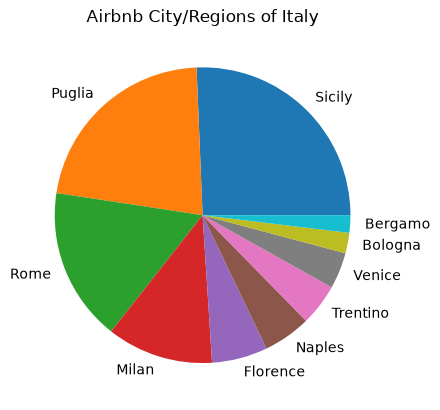

In [3]:
# Airbnb Pie Chart representation that covers the following Italian regions/cities
plt.pie(df['city_region'].value_counts(), labels=df['city_region'].value_counts().index)
plt.title('Airbnb City/Regions of Italy')
plt.show()

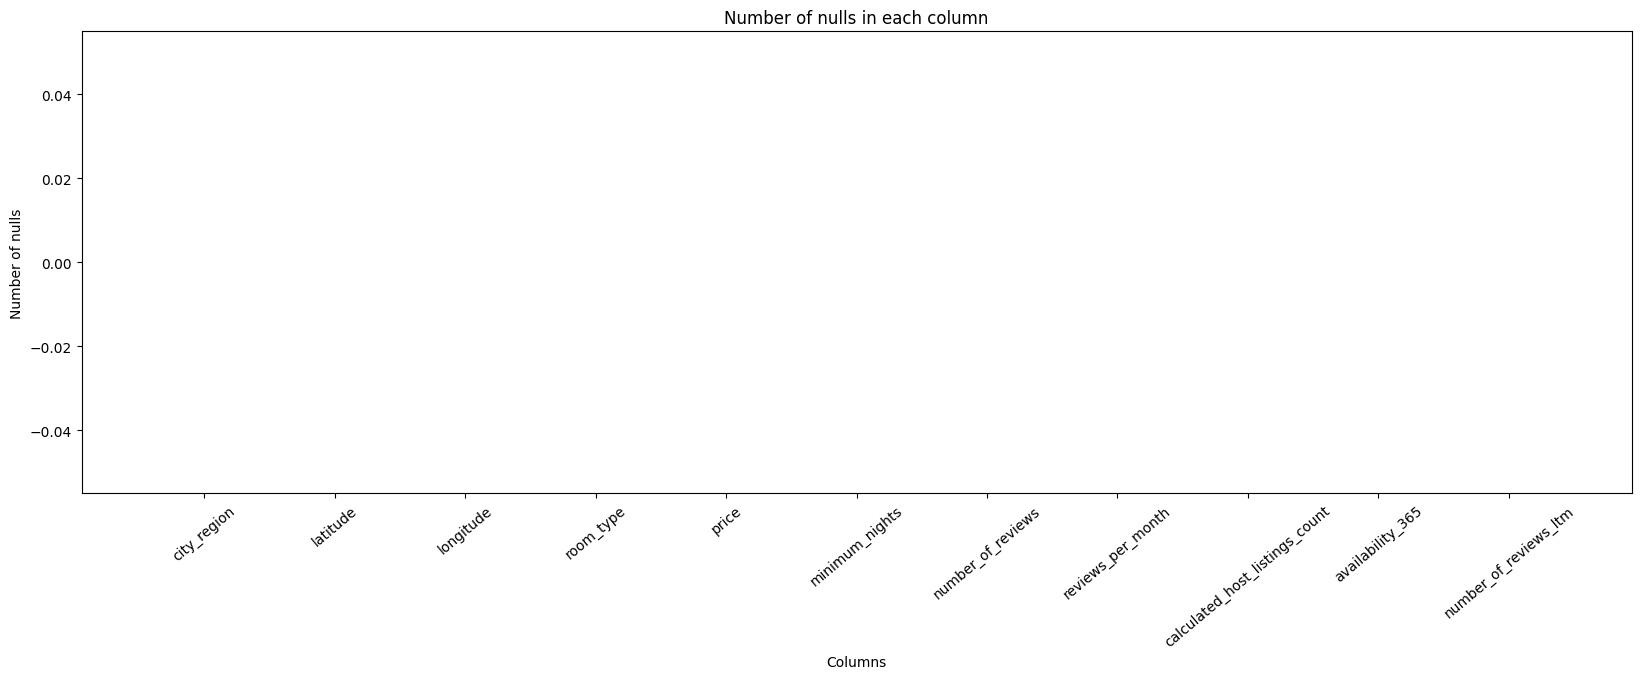

In [30]:

plt.figure(figsize=(20,6))
plt.bar(df.isnull().sum().index, df.isnull().sum().values)
plt.title('Number of nulls in each column')
plt.xticks(rotation=40)
plt.xlabel('Columns')
plt.ylabel('Number of nulls')
plt.show()

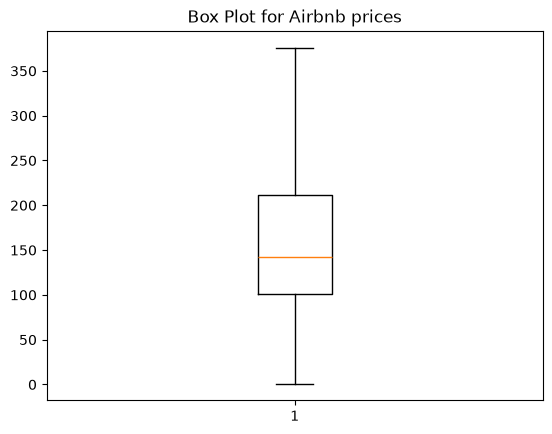

In [5]:
# Box plot for Airbnb price
plt.boxplot(df['price'].dropna(), showfliers=False)
plt.title('Box Plot for Airbnb prices')
plt.show()

In [6]:
#fig, axes = plt.subplots(3, 3)
#fig.set_size_inches(15, 10)
#for i in range(len(df.columns)):
#    col = df.columns[i]
#    ax = axes[i // 3, i % 3]
#    data = df[col].dropna()
#    data = data[data <= data.quantile(0.99)]      # trim the extreme values
#    ax.hist(data, bins=40)
#    ax.set_title(col)
#    ax.set_xlabel(col)
#    ax.set_ylabel('Number of listings')
#fig.suptitle('Histograms of numerical variables (up to the 99th percentile)')
#fig.tight_layout()
#plt.show()

## Data Preprocessing

#### Data duplicates

In [7]:
df.duplicated().sum()

np.int64(13)

#### Converting input features with incorrect data types to correct data types

In [8]:
df[['city_region', 'neighbourhood_group', 'neighbourhood', 'room_type']] = df[['city_region', 'neighbourhood_group', 'neighbourhood', 'room_type']].astype('category')
df['last_review'] = pd.to_datetime(df['last_review'])
print(df['room_type'].dtype)
print(df['city_region'].dtype)
print(df['neighbourhood_group'].dtype)
print(df['neighbourhood'].dtype)
print(df['last_review'].dtype)


category
category
category
category
datetime64[us]


#### Invalid, impossible or inconsistent values

In [9]:
# Missing values
df[['price', 'calculated_host_listings_count', 'reviews_per_month']].isnull().sum()
print(df[['price', 'calculated_host_listings_count', 'reviews_per_month']].isnull().sum())

# Irrelevant values
df[df['minimum_nights'] > 365].shape

price                             20690
calculated_host_listings_count      275
reviews_per_month                 49451
dtype: int64


(19, 20)

#### Irrelevant features

In [10]:
df.drop(columns=['name', 'id', 'host_id', 'neighbourhood_group', 'host_profile_id', 'host_name', 'last_review', 'license'])

,city_region,neighbourhood,latitude,longitude,room_type,price,minimum_nights,number_of_reviews,reviews_per_month,calculated_host_listings_count,availability_365,number_of_reviews_ltm
0,Bergamo,Nembro,45.749750,9.756680,Private room,285.0,1.0,0,NaN,NaN,136,0
1,Bergamo,Caravaggio,45.496000,9.645330,Entire home/apt,1.0,270.0,0,NaN,2.0,358,0
2,Bergamo,Bergamo,45.707810,9.658210,Entire home/apt,NaN,31.0,43,0.32,1.0,3,0
3,Bergamo,Solto Collina,45.786140,10.041430,Entire home/apt,51.0,80.0,0,NaN,1.0,365,0
4,Bergamo,Bergamo,45.689750,9.668520,Entire home/apt,NaN,31.0,5,0.13,1.0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...
221742,Venice,Dorsoduro,45.430470,12.328570,Entire home/apt,982.0,1.0,0,NaN,86.0,288,0
221743,Venice,Dorsoduro,45.430352,12.328994,Entire home/apt,223.0,2.0,2,0.10,3.0,84,1
221744,Venice,Cannaregio,45.445380,12.326630,Entire home/apt,211.0,4.0,6,0.06,1.0,148,0
221745,Venice,San Marco,45.433780,12.336220,Entire home/apt,263.0,1.0,24,0.25,6.0,298,1


#### Constant or near-constant variables

In [11]:
df['room_type'].value_counts(normalize=True)

room_type
Entire home/apt    0.796187
Private room       0.197572
Hotel room         0.004564
Shared room        0.001678
Name: proportion, dtype: float64

##### High-cardinality categories

In [12]:
df['neighbourhood'].nunique()

1025